# 1. Imports

In [1]:
from pathlib import Path 
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report  ,confusion_matrix , ConfusionMatrixDisplay
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model  import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# 2. Global parameters

In [2]:
RANDOM_STATE=24 #REMEMBER: remove at the time of promotion to production
rng = np.random.default_rng(seed=RANDOM_STATE)

NOISE=0.2
EPOCHS=20001
ALPHA=0.1
N_SAMPLE= 1000
TEST_SIZE=0.2

params = {
    'legend.fontsize': 'medium',
    'figure.figsize' : (15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium',

}

plt.rcParams.update(params)
CMAP= plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') #plt.style.use('ggplot')

## Helper Function

In [3]:
X,y= datasets.make_moons(n_samples=N_SAMPLE,shuffle= True, noise=NOISE,random_state=RANDOM_STATE)
X[:5],y[:5]                       

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 2) (200, 2) (800,) (200,)


## Different Plots

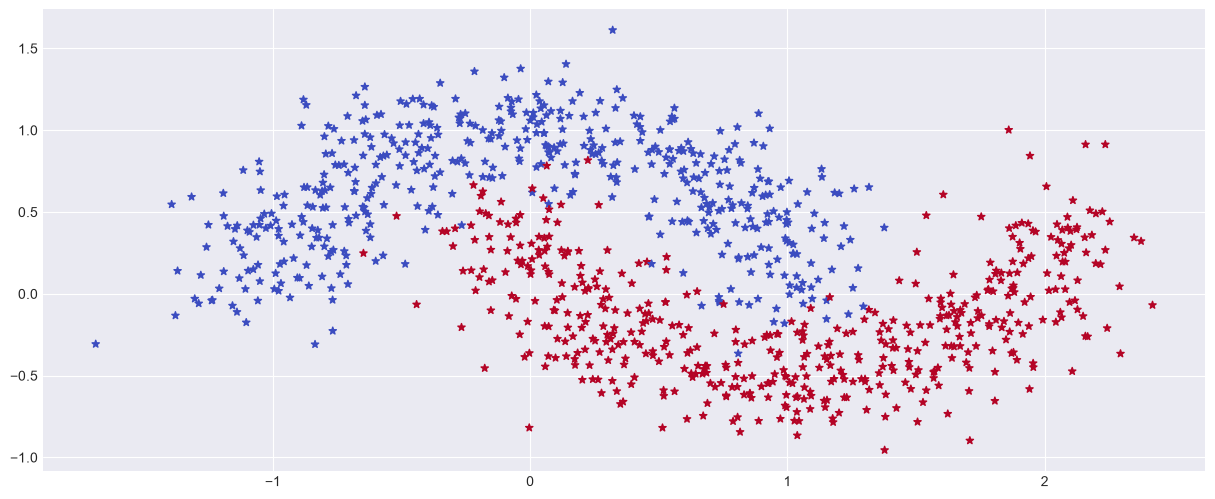

In [5]:
plt.figure()
plt.scatter(X[:,0],X[:,1],s=30,c=y,marker="*",cmap=CMAP)

## Sigmoid Activation Fucntion

In [6]:
def fn_sigmoid(z):
    return 1 / (1+np.exp(-z))

In [7]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

## Tanh Activation Function

In [8]:
def fn_activ(z:np.ndarray)-> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z:np.ndarray)->np.ndarray:
    return  1.0 - np.tanh(z)**2

In [9]:
fn_activ(np.asarray([[-1,0,1],[-np.inf,0,np.inf]]))

array([[-0.76159416,  0.        ,  0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [10]:
 def fn_predict(model: dict, X:np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X_p: Input features
    '''
    W1,W2 = model['W1'],model['W2']
    b1,b2 = model['b1'],model['b2']
    ### Forward propagation
    
    #Layer 1
    z1 = X.dot(W1) + b1 #aggregation
    a1 = fn_activ(z1) #Activation   (Tanh)
    #Layer 2
    z2 = a1.dot(W2) + b2 #aggregation
    a2 = fn_sigmoid(z2) #Activation  (Sigmoid)
    
    return a2 >=0.5

In [11]:
def fn_calculate_loss(model: dict, X_l:np.ndarray,y_l:np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X_l: input features
    y_l:targets
    '''
    m=X_l.shape[0]
    W1,W2 = model['W1'],model['W2']
    b1,b2 = model['b1'],model['b2']
    ### Forward propagation
    
    #Layer 1
    z1 = X_l.dot(W1) + b1 #aggregation
    a1 = fn_activ(z1) #Activation   (Tanh)
    #Layer 2
    z2 = a1.dot(W2) + b2 #aggregation
    a2 = fn_sigmoid(z2) #Activation  (Sigmoid)
    data_loss = -( y_l * np.log( a2 ) + ( 1 - y_l ) * np.log( 1 - a2 ) ).sum()
    
    return data_loss / m

In [12]:
def fn_build_model(nn_hdim: np.int64,
                   X: np.ndarray,
                   y: np.ndarray,
                   alpha: np.float64=ALPHA,
                   n_epochs: np.int64=EPOCHS
                  ) -> dict:

    '''
        nn_hdim: number of hidden units,
        X: features,
        y: labels,
        alpha: learning rate,
        n_epochs: number of passes through complete data for gradient descent
    '''

    m,nn_input_dim = X.shape
    nn_output_dim = y.shape[1]

    W1 = rng.random((nn_input_dim, nn_hdim),dtype=np.float32) / np.sqrt(nn_input_dim)
    W2 = rng.random((nn_hdim, nn_output_dim),dtype=np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1,nn_hdim),dtype=np.float32)
    b2 = np.zeros((1,nn_output_dim),dtype=np.float32)
    
    curr_loss = 0 
    loss,epoch = [],[]

    for i in range(n_epochs):  #loop for number of epochs

        ### Forward propagation
     
         #Layer 1
         z1 = X.dot(W1) + b1 #aggregation
         a1 = fn_activ(z1) #Activation   (Tanh)

         #Layer 2
         z2 = a1.dot(W2) + b2 #aggregation
         a2 = fn_sigmoid(z2) #Activation  (Sigmoid)

        ### Backward Propagation

        #Layer 2
         dz2 = a2-y
         dW2 = (a1.T).dot(dz2)# T => Transpose
         assert(W2.shape == dW2.shape), f'Shape: W2 {W2.shape} | dW2: {dW2.shape}'
         db2 = np.sum(dz2,axis=0,keepdims=True) ## so that we mentain the dimension
         assert(b2.shape == db2.shape), f'Shape: b2 {b2.shape} | dW2: {db2.shape}'
         da1 = dz2.dot(W2.T)
         assert(a1.shape == da1.shape), f'Shape: a1 {a1.shape} | da1: {da1.shape}'

        #Layer 1
         dz1 = da1*fn_activ_prime(z1)
         dW1 = (X.T).dot(dz1)
         assert(W1.shape == dW1.shape), f'Shape: w1 {W1.shape} | dw1: {dW1.shape}'
         db1 = np.sum(dz1,axis=0,keepdims=True)
         assert(b1.shape == db1.shape), f'Shape: b1 {b1.shape} | db1: {db1.shape}'

         #gradient updates
         W1 = W1 -alpha * dW1 / m
         W2 = W2 -alpha * dW2 / m
         b1 = b1 -alpha * db1 / m
         b2 = b2 -alpha * db2 / m

         model = {'W1':W1,'W2':W2,'b1':b1,'b2':b2}
         
         
         if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model,X_l=X,y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")
    loss_hist['epoch'] = epoch
    loss_hist['loss'] = loss
    return model

In [13]:
loss_hist = {}
y_train = y_train.reshape(-1,1)
model = fn_build_model(5,X_train,y_train)

Epoch   0: Loss = 0.6858
Epoch 100: Loss = 0.4437
Epoch 200: Loss = 0.3359
Epoch 300: Loss = 0.3055
Epoch 400: Loss = 0.2983
Epoch 500: Loss = 0.2963
Epoch 600: Loss = 0.2955
Epoch 700: Loss = 0.2950
Epoch 800: Loss = 0.2947
Epoch 900: Loss = 0.2943
Epoch 1000: Loss = 0.2940
Epoch 1100: Loss = 0.2936
Epoch 1200: Loss = 0.2933
Epoch 1300: Loss = 0.2929
Epoch 1400: Loss = 0.2924
Epoch 1500: Loss = 0.2918
Epoch 1600: Loss = 0.2910
Epoch 1700: Loss = 0.2899
Epoch 1800: Loss = 0.2882
Epoch 1900: Loss = 0.2858
Epoch 2000: Loss = 0.2820
Epoch 2100: Loss = 0.2765
Epoch 2200: Loss = 0.2691
Epoch 2300: Loss = 0.2598
Epoch 2400: Loss = 0.2492
Epoch 2500: Loss = 0.2381
Epoch 2600: Loss = 0.2272
Epoch 2700: Loss = 0.2169
Epoch 2800: Loss = 0.2073
Epoch 2900: Loss = 0.1986
Epoch 3000: Loss = 0.1907
Epoch 3100: Loss = 0.1836
Epoch 3200: Loss = 0.1770
Epoch 3300: Loss = 0.1710
Epoch 3400: Loss = 0.1655
Epoch 3500: Loss = 0.1604
Epoch 3600: Loss = 0.1556
Epoch 3700: Loss = 0.1510
Epoch 3800: Loss = 0.1

<Axes: xlabel='epoch'>

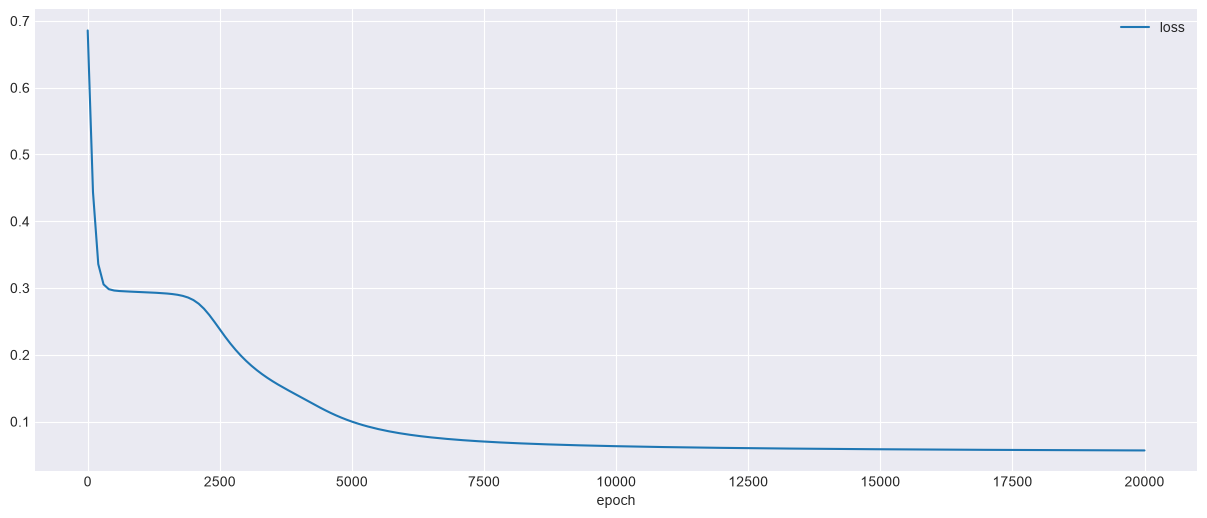

In [14]:
loss_df = pd.DataFrame(loss_hist)
fig , ax = plt.subplots()
loss_df.plot(x='epoch',y='loss',ax=ax)

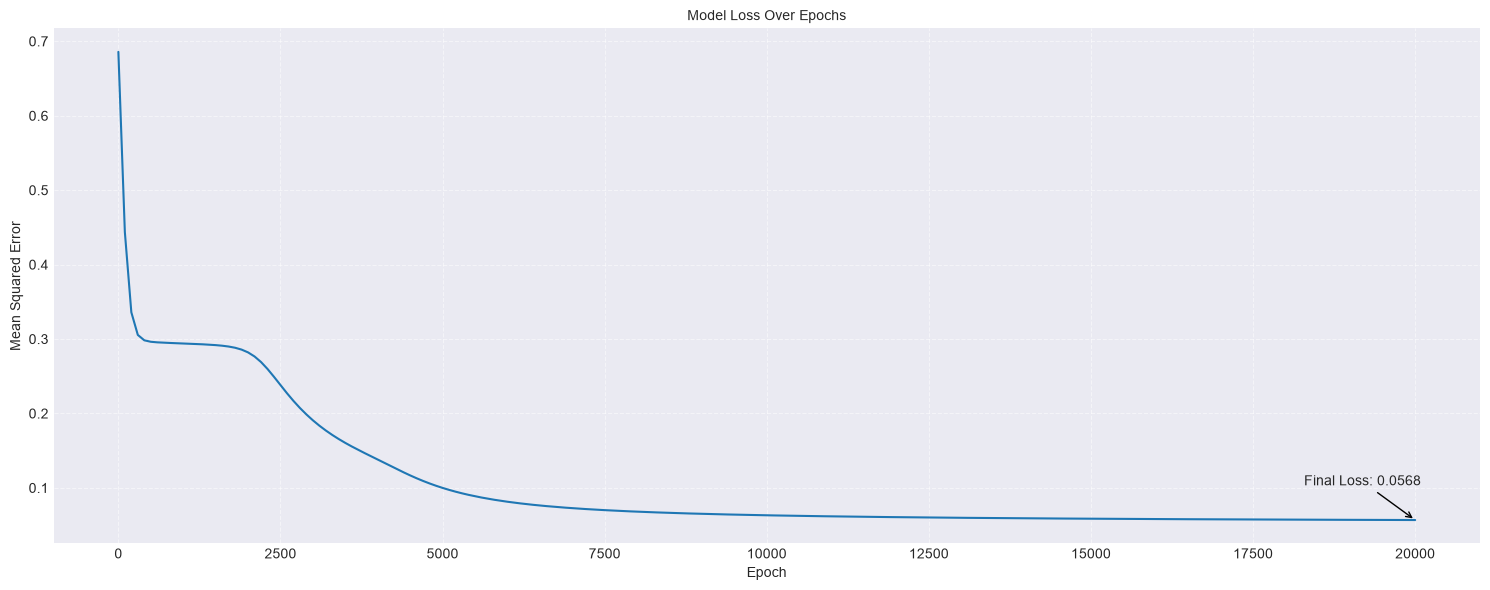

In [15]:
fig, ax = plt.subplots()
# Plot training loss line
ax.plot(loss_df['epoch'], loss_df['loss'], color='#1f77b4',  label='Training Loss')
# Titles and axis labels
ax.set_title('Model Loss Over Epochs')
ax.set_xlabel('Epoch')
ax.set_ylabel('Mean Squared Error')
# Subtle grid and clean borders
ax.grid(True, linestyle='--', alpha=0.5)
final_loss = loss_df['loss'].iloc[-1]
final_epoch = loss_df['epoch'].iloc[-1]
ax.annotate(f'Final Loss: {final_loss:.4f}', 
            xy=(final_epoch, final_loss),  # Fixed: Use the actual final epoch number
            xytext=(-80, 25), textcoords='offset points',
            arrowprops=dict(arrowstyle='->')
           )
plt.tight_layout()
plt.show()


In [16]:
def plot_decision_boundary(
    model: dict,
    X_tr:np.ndarray,
    y_tr:np.ndarray,
    X_ts:np.ndarray,
    y_ts:np.ndarray):
    
    fig , ax = plt.subplots()
    dm=0.005
    margin = 10*dm
    
    xMin = min(X_tr[:,0].min() - margin,X_ts[:,0].min() - margin)
    xMax = max(X_tr[:,0].max() + margin,X_ts[:,0].max() + margin)
    
    yMin = min(X_tr[:,1].min() - margin,X_ts[:,1].min() - margin)
    yMax = max(X_tr[:,1].max() + margin,X_ts[:,1].max() + margin)
    
    xx, yy = np.meshgrid(np.arange(xMin , xMax,dm),
                         np.arange(yMin , yMax,dm))
    
    XX = np.c_[xx.ravel(),yy.ravel()]
    Z = fn_predict(model,XX).reshape(xx.shape)


    ax.contourf(xx,yy,Z,cmap= plt.cm.Paired , alpha = 0.6)
    ax.scatter(X_tr[:,0],X_tr[:,1],c=y_tr, s =30 , edgecolors='k', cmap= CMAP)
    ax.scatter(X_ts[:,0],X_ts[:,1],c=y_ts, s =30 ,marker='*', edgecolors='k', cmap=plt.cm.seismic)

    ax.set_xlabel('feature 1')
    ax.set_ylabel('feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

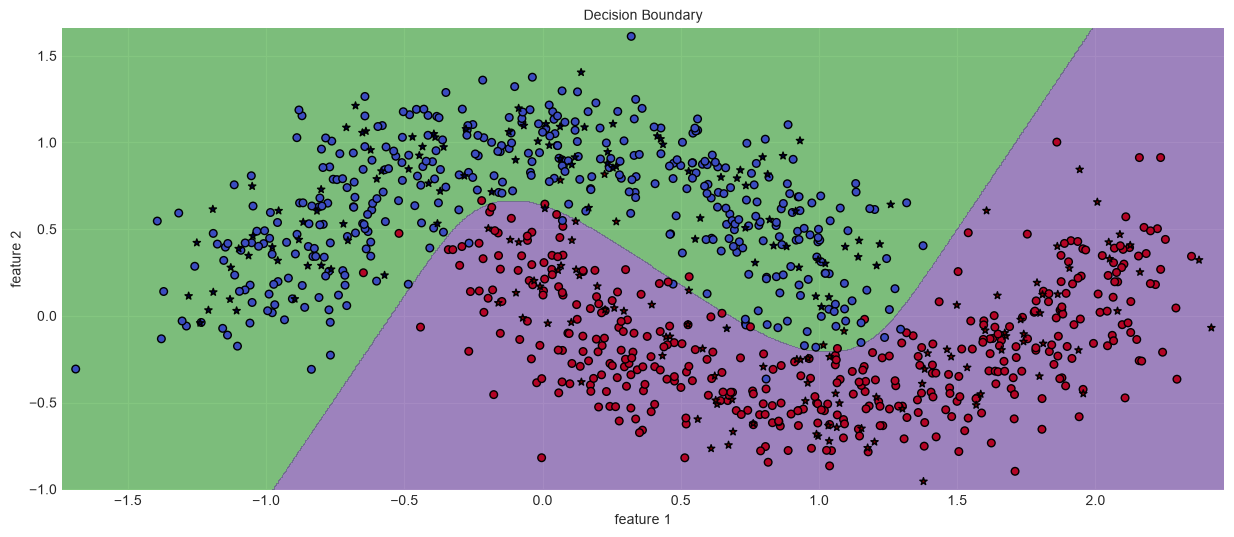

In [17]:
plot_decision_boundary(model,X_train,y_train, X_test,y_test)

In [18]:
#training accuracy
predictions = []
for row in X_train:
    a = fn_predict(model, row.reshape(1, -1))
    y_p = 1 if a >= 0.5 else 0
    predictions.append(y_p)

accuracy_score(y_train.ravel(), predictions)

0.9825

In [19]:
#test accuracy
predictions = []
for row in X_test:
    a = fn_predict(model, row.reshape(1, -1))
    y_p = 1 if a >= 0.5 else 0
    predictions.append(y_p)

accuracy_score(y_test.ravel(), predictions)

0.965

[[98  2]
 [ 5 95]]


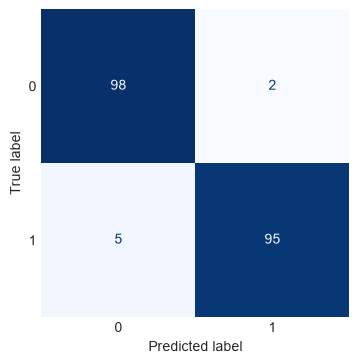

In [20]:
test_preds = fn_predict(model, X_test).astype(int)
cm = confusion_matrix(y_test.ravel(), test_preds)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.grid(False)  
plt.show()